# 01 - Análise Exploratória de Dados (EDA)

Neste notebook realizamos uma análise completa do dataset de risco de doenças cardíacas.

## Importar bibliotecas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Configurar estilo dos gráficos
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

## 1. Carregamento e Inspeção Inicial

In [2]:
# Carregar o dataset
df = pd.read_csv('../data/raw/dataset.csv')

print("Primeiras linhas do dataset:")
print(df.head())

Primeiras linhas do dataset:
   patient_id  age     sex  resting_bp_systolic  resting_bp_diastolic  \
0           1   44    Male                  117                    74   
1           2   57    Male                  139                    94   
2           3   29    Male                  128                    78   
3           4   72    Male                  132                    86   
4           5   62  Female                  116                    75   

   cholesterol_total  hdl  ldl  triglycerides  fasting_blood_sugar  ...  \
0                193   57  106            119                  112  ...   
1                185   69  110             35                  114  ...   
2                197   52  108            157                   95  ...   
3                197   59  104            143                   92  ...   
4                154   65   75            104                  135  ...   

   family_history  smoker_status  alcohol_units_per_week  \
0           False    

In [3]:
print("\nÚltimas linhas do dataset:")
print(df.tail())


Últimas linhas do dataset:
      patient_id  age     sex  resting_bp_systolic  resting_bp_diastolic  \
8995        8996   36  Female                  108                    63   
8996        8997   44  Female                  112                    73   
8997        8998   57  Female                  144                    93   
8998        8999   61  Female                  130                    70   
8999        9000   63  Female                  152                   104   

      cholesterol_total  hdl  ldl  triglycerides  fasting_blood_sugar  ...  \
8995                178   68   82            158                   96  ...   
8996                213   54  139            102                  125  ...   
8997                198   66  113             79                  102  ...   
8998                220   68  135            109                  104  ...   
8999                215   64  117            109                  120  ...   

      family_history  smoker_status  alcohol_u

In [4]:
print("\nDimensões do dataset:")
print(f"Linhas: {df.shape[0]}")
print(f"Colunas: {df.shape[1]}")


Dimensões do dataset:
Linhas: 9000
Colunas: 27


In [5]:
print("\nTipos de dados:")
print(df.dtypes)


Tipos de dados:
patient_id                     int64
age                            int64
sex                           object
resting_bp_systolic            int64
resting_bp_diastolic           int64
cholesterol_total              int64
hdl                            int64
ldl                            int64
triglycerides                  int64
fasting_blood_sugar            int64
hba1c                        float64
bmi                          float64
resting_heart_rate             int64
max_heart_rate_achieved        int64
chest_pain_type               object
exercise_induced_angina         bool
st_depression                float64
family_history                  bool
smoker_status                 object
alcohol_units_per_week       float64
exercise_minutes_per_week      int64
sleep_hours                  float64
stress_score                 float64
wearable_owner                  bool
daily_steps                    int64
diet_quality_score           float64
has_heart_disease    

## 2. Estatísticas Descritivas

In [6]:
print("Resumo estatístico das variáveis numéricas:")
print(df.describe())

Resumo estatístico das variáveis numéricas:
        patient_id          age  resting_bp_systolic  resting_bp_diastolic  \
count  9000.000000  9000.000000          9000.000000           9000.000000   
mean   4500.500000    53.977333           127.849778             80.788778   
std    2598.220545    13.008051            13.767233             10.939943   
min       1.000000    18.000000            85.000000             50.000000   
25%    2250.750000    45.000000           119.000000             74.000000   
50%    4500.500000    54.000000           128.000000             81.000000   
75%    6750.250000    63.000000           137.000000             88.000000   
max    9000.000000    90.000000           181.000000            126.000000   

       cholesterol_total          hdl          ldl  triglycerides  \
count        9000.000000  9000.000000  9000.000000    9000.000000   
mean          188.753556    55.215333   103.275556     152.045000   
std            32.271644    12.394400    27.34

In [ ]:
print("\nVariáveis categóricas:")
for col in df.select_dtypes(include=['object']).columns:
    print(f"\n{col}:")
    print(df[col].value_counts())

## 3. Identificação de Valores Ausentes

In [7]:
# Calcular valores ausentes
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    'Coluna': missing.index,
    'Valores_Ausentes': missing.values,
    'Percentual': missing_pct.values
}).sort_values('Valores_Ausentes', ascending=False)

print("\nValores ausentes por coluna:")
print(missing_df)


Valores ausentes por coluna:
                       Coluna  Valores_Ausentes  Percentual
0                  patient_id                 0         0.0
1                         age                 0         0.0
2                         sex                 0         0.0
3         resting_bp_systolic                 0         0.0
4        resting_bp_diastolic                 0         0.0
5           cholesterol_total                 0         0.0
6                         hdl                 0         0.0
7                         ldl                 0         0.0
8               triglycerides                 0         0.0
9         fasting_blood_sugar                 0         0.0
10                      hba1c                 0         0.0
11                        bmi                 0         0.0
12         resting_heart_rate                 0         0.0
13    max_heart_rate_achieved                 0         0.0
14            chest_pain_type                 0         0.0
15    exer

In [8]:
# Visualizar valores ausentes
plt.figure(figsize=(12, 6))
missing_data = df.isnull().sum()
missing_data = missing_data[missing_data > 0]

if len(missing_data) > 0:
    missing_data.plot(kind='barh', color='coral')
    plt.xlabel('Quantidade de Valores Ausentes')
    plt.title('Valores Ausentes por Coluna')
    plt.tight_layout()
    plt.savefig('../reports/figures/missing_values.png', dpi=100, bbox_inches='tight')
    plt.show()
else:
    print("Não há valores ausentes no dataset!")

Não há valores ausentes no dataset!


<Figure size 1200x600 with 0 Axes>

## 4. Detecção de Outliers

In [9]:
# Função para detectar outliers usando IQR
def detectar_outliers_iqr(data, coluna):
    Q1 = data[coluna].quantile(0.25)
    Q3 = data[coluna].quantile(0.75)
    IQR = Q3 - Q1
    limite_inf = Q1 - 1.5 * IQR
    limite_sup = Q3 + 1.5 * IQR
    return (data[coluna] < limite_inf) | (data[coluna] > limite_sup)

# Detectar outliers
numericas = df.select_dtypes(include=[np.number]).columns
outliers_por_coluna = {}

for col in numericas:
    outliers = detectar_outliers_iqr(df, col)
    outliers_por_coluna[col] = outliers.sum()

outliers_df = pd.DataFrame({
    'Coluna': list(outliers_por_coluna.keys()),
    'Quantidade_Outliers': list(outliers_por_coluna.values())
}).sort_values('Quantidade_Outliers', ascending=False)

print("\nOutliers detectados (método IQR):")
print(outliers_df[outliers_df['Quantidade_Outliers'] > 0])


Outliers detectados (método IQR):
                       Coluna  Quantidade_Outliers
13              st_depression                  485
14     alcohol_units_per_week                  431
16                sleep_hours                   86
3        resting_bp_diastolic                   75
17               stress_score                   71
19         diet_quality_score                   69
2         resting_bp_systolic                   66
5                         hdl                   63
4           cholesterol_total                   50
11         resting_heart_rate                   42
7               triglycerides                   42
10                        bmi                   39
6                         ldl                   34
8         fasting_blood_sugar                   32
18                daily_steps                   32
15  exercise_minutes_per_week                   27
12    max_heart_rate_achieved                   17
9                       hba1c                  

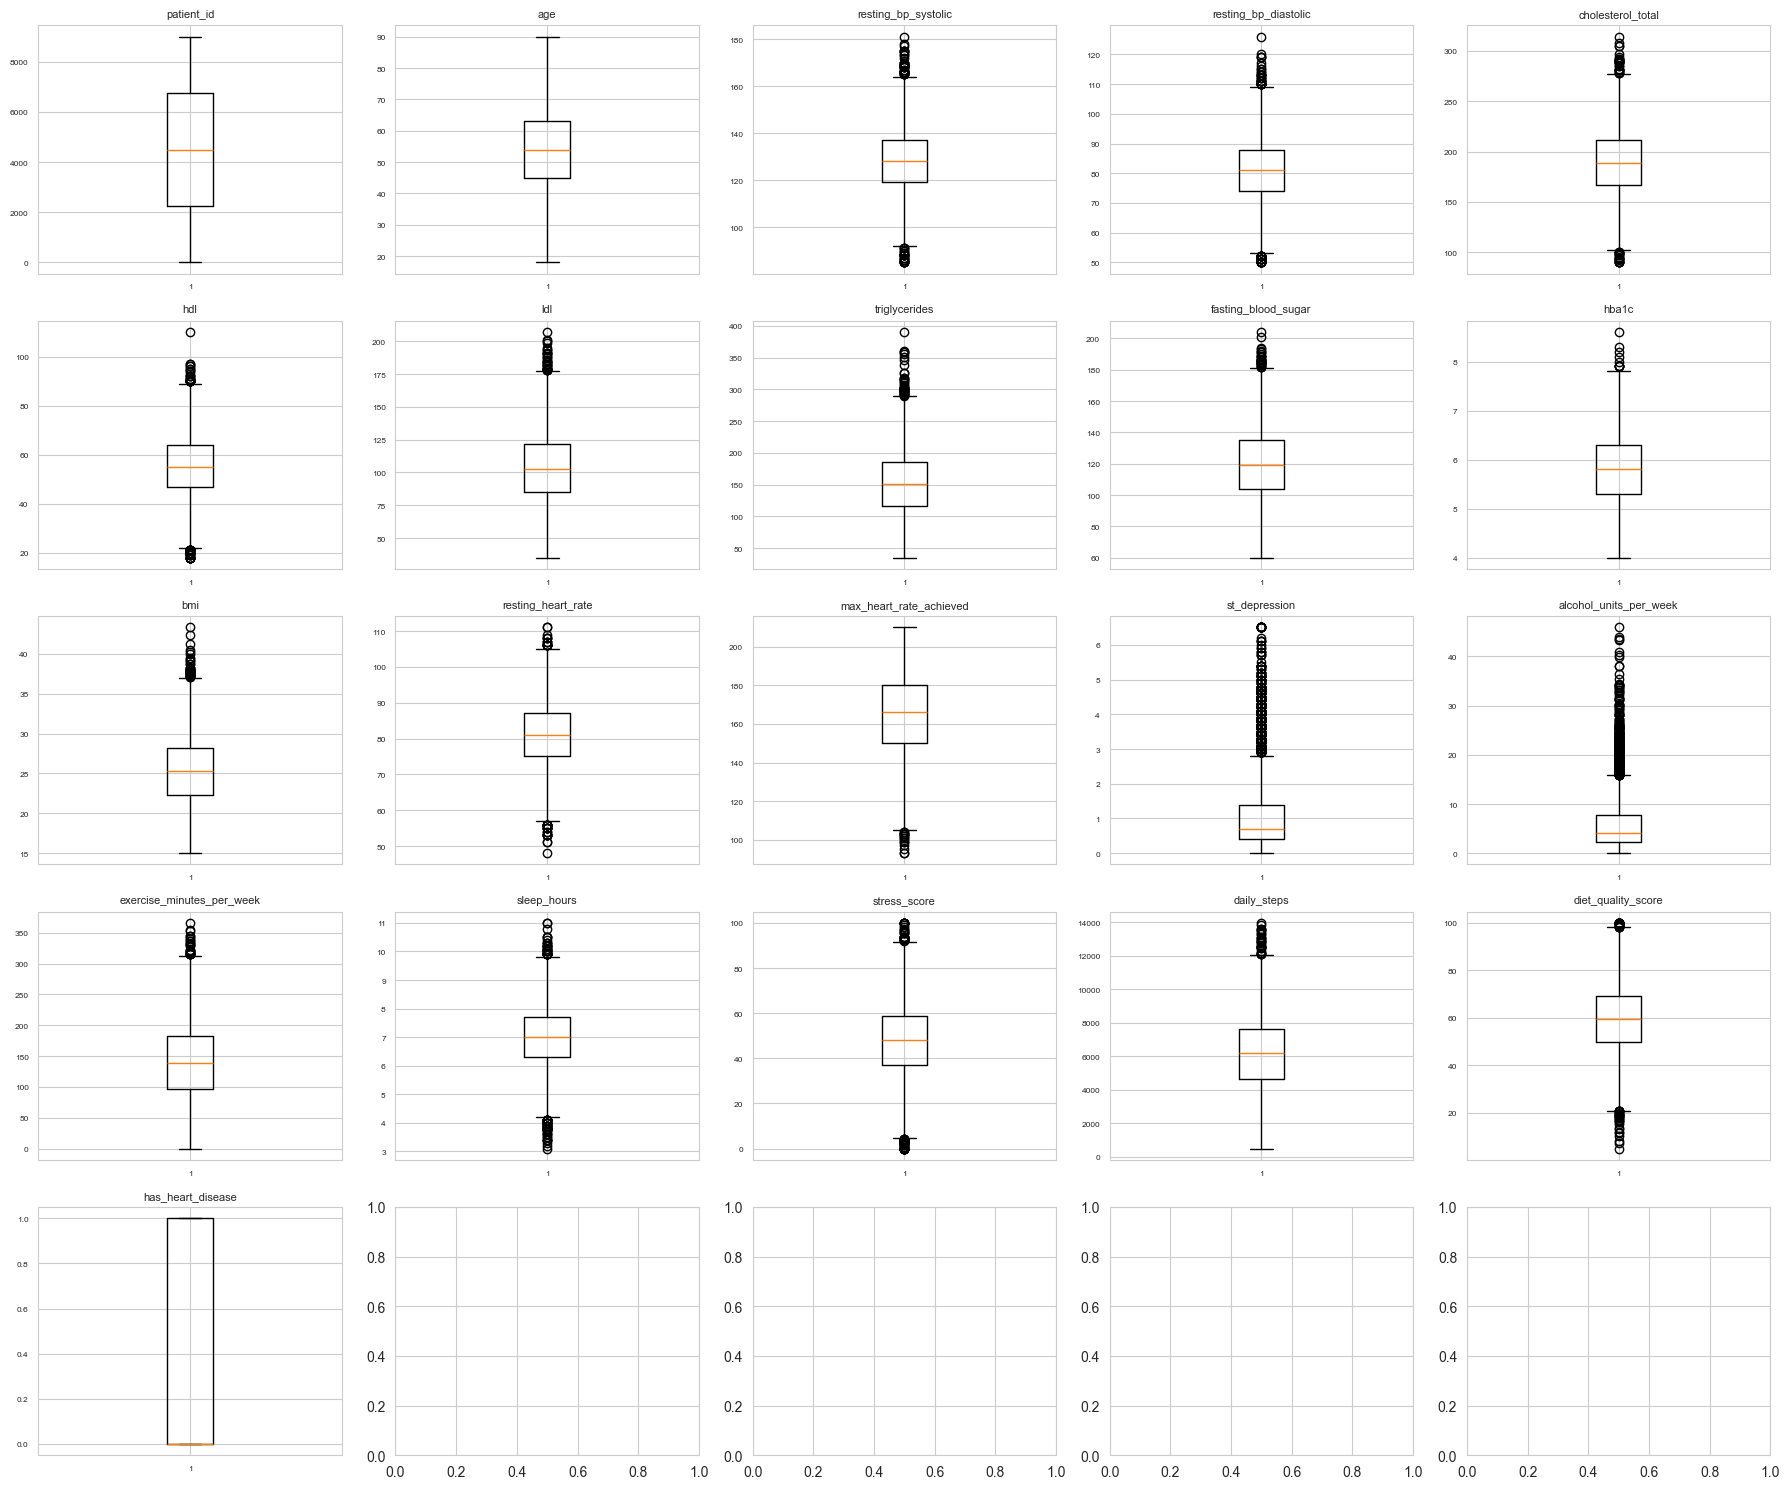

In [10]:
# Boxplot para visualizar outliers
fig, axes = plt.subplots(5, 5, figsize=(18, 15))
axes = axes.flatten()

for idx, col in enumerate(numericas[:25]):
    axes[idx].boxplot(df[col].dropna())
    axes[idx].set_title(col, fontsize=8)
    axes[idx].tick_params(labelsize=6)

plt.tight_layout()
plt.savefig('../reports/figures/outliers_boxplot.png', dpi=100, bbox_inches='tight')
plt.show()

## 5. Análise de Correlação

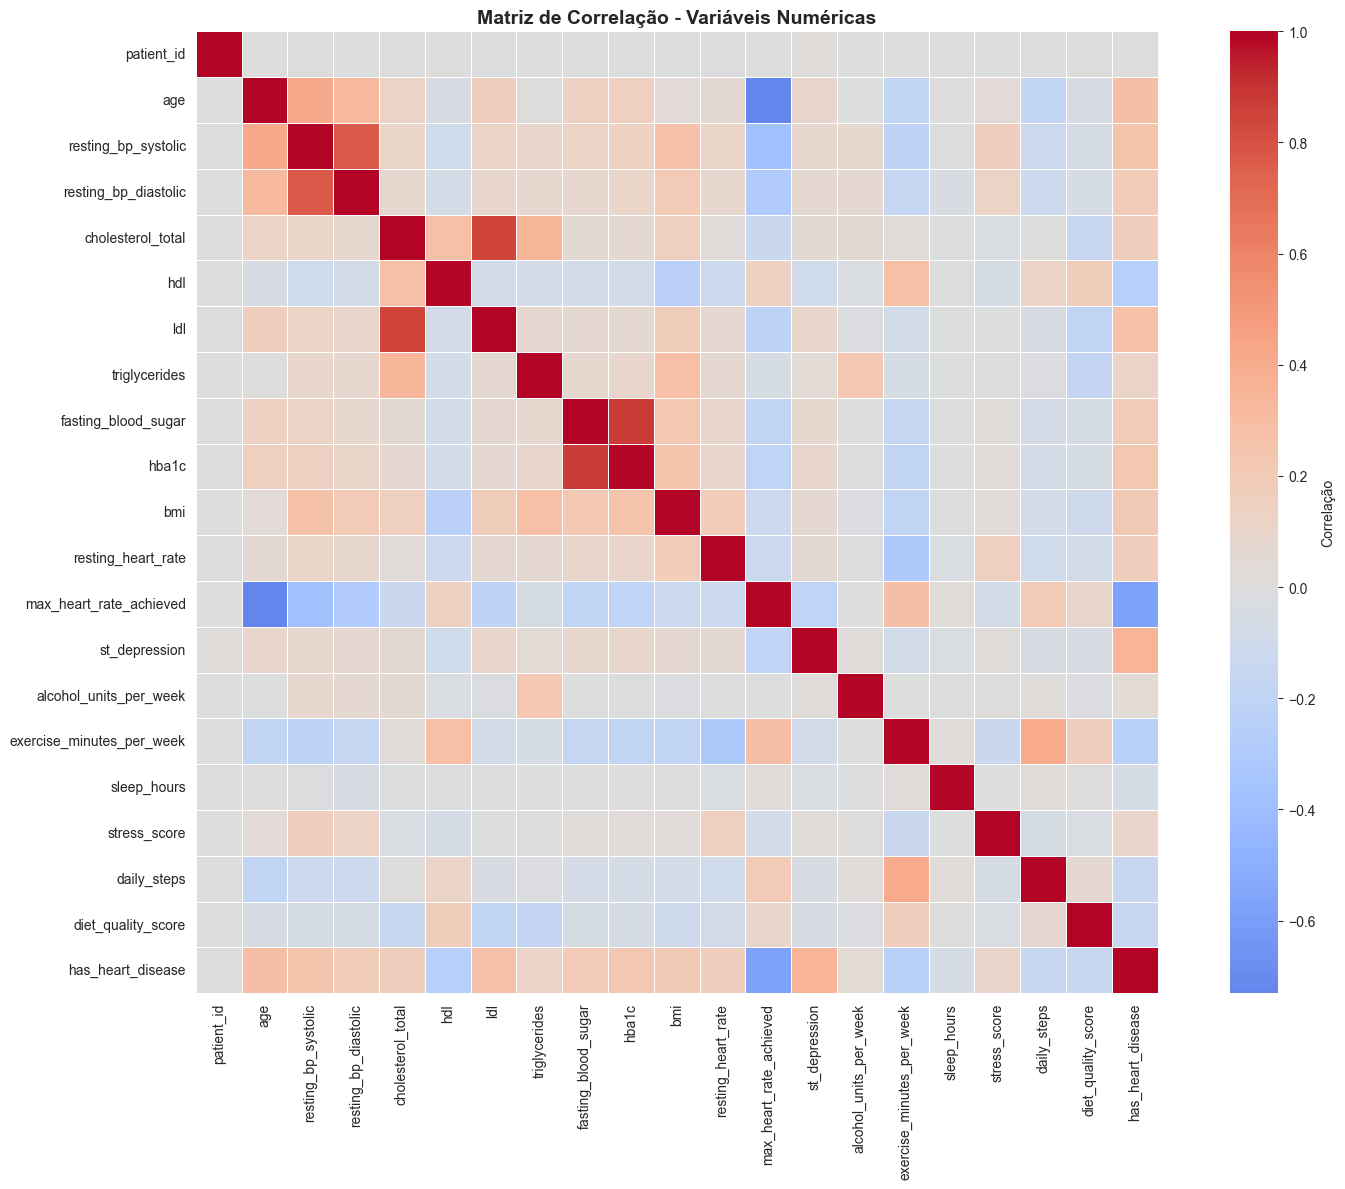

In [11]:
# Calcular matriz de correlação
corr_matrix = df[numericas].corr()

# Visualizar matriz de correlação
plt.figure(figsize=(16, 12))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', center=0, 
            square=True, linewidths=0.5, cbar_kws={'label': 'Correlação'})
plt.title('Matriz de Correlação - Variáveis Numéricas', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/correlation_matrix.png', dpi=100, bbox_inches='tight')
plt.show()

In [12]:
# Encontrar pares com alta correlação
def encontrar_correlacoes_altas(corr_matrix, threshold=0.7):
    pares = []
    for i in range(len(corr_matrix.columns)):
        for j in range(i+1, len(corr_matrix.columns)):
            if abs(corr_matrix.iloc[i, j]) >= threshold:
                pares.append({
                    'Var1': corr_matrix.columns[i],
                    'Var2': corr_matrix.columns[j],
                    'Correlação': corr_matrix.iloc[i, j]
                })
    return pd.DataFrame(pares).sort_values('Correlação', ascending=False, key=abs)

altas_corr = encontrar_correlacoes_altas(corr_matrix, threshold=0.7)
print("\nPares de variáveis com alta correlação (|r| >= 0.7):")
print(altas_corr)


Pares de variáveis com alta correlação (|r| >= 0.7):
                  Var1                     Var2  Correlação
3  fasting_blood_sugar                    hba1c    0.877319
2    cholesterol_total                      ldl    0.841361
1  resting_bp_systolic     resting_bp_diastolic    0.767131
0                  age  max_heart_rate_achieved   -0.730663


## 6. Visualizações dos Dados

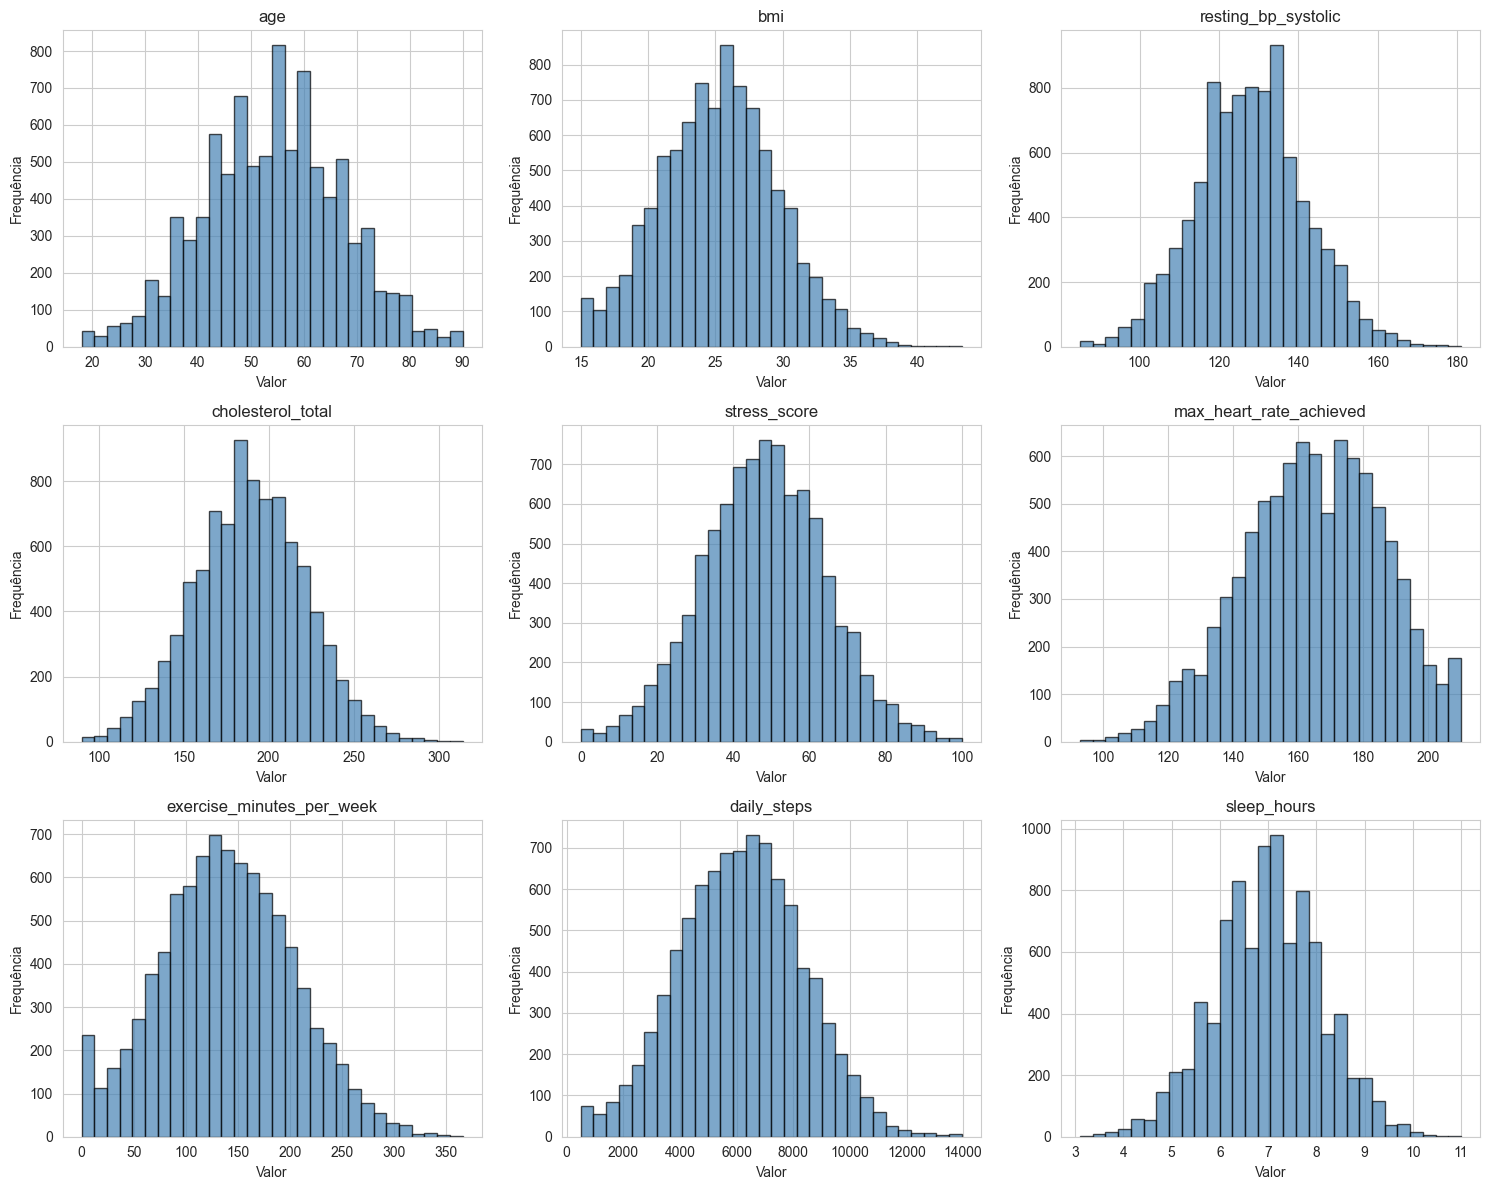

In [13]:
# Histogramas das principais variáveis
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

principais_vars = ['age', 'bmi', 'resting_bp_systolic', 'cholesterol_total', 
                   'stress_score', 'max_heart_rate_achieved', 'exercise_minutes_per_week',
                   'daily_steps', 'sleep_hours']

for idx, col in enumerate(principais_vars):
    axes[idx].hist(df[col].dropna(), bins=30, color='steelblue', edgecolor='black', alpha=0.7)
    axes[idx].set_title(col)
    axes[idx].set_xlabel('Valor')
    axes[idx].set_ylabel('Frequência')

plt.tight_layout()
plt.show()

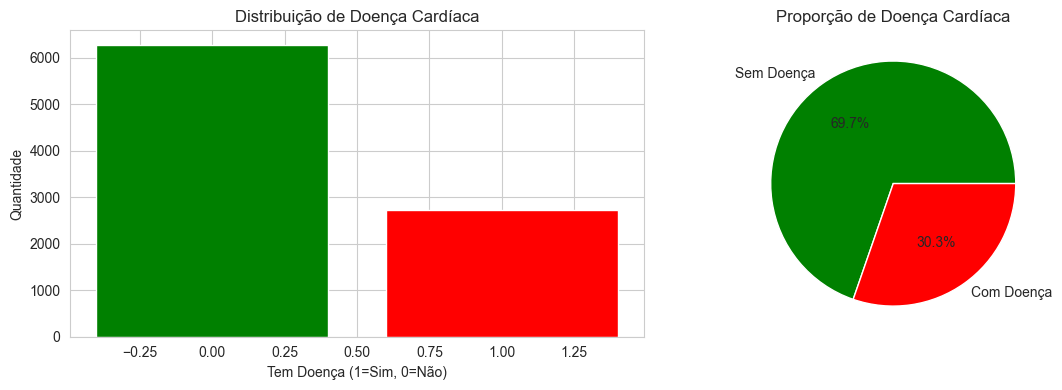

In [14]:
# Distribuição da variável alvo (has_heart_disease)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Contagem
axes[0].bar(df['has_heart_disease'].value_counts().index, 
            df['has_heart_disease'].value_counts().values, color=['green', 'red'])
axes[0].set_title('Distribuição de Doença Cardíaca')
axes[0].set_xlabel('Tem Doença (1=Sim, 0=Não)')
axes[0].set_ylabel('Quantidade')

# Percentual
axes[1].pie(df['has_heart_disease'].value_counts().values, 
            labels=['Sem Doença', 'Com Doença'], autopct='%1.1f%%',
            colors=['green', 'red'])
axes[1].set_title('Proporção de Doença Cardíaca')

plt.tight_layout()
plt.show()

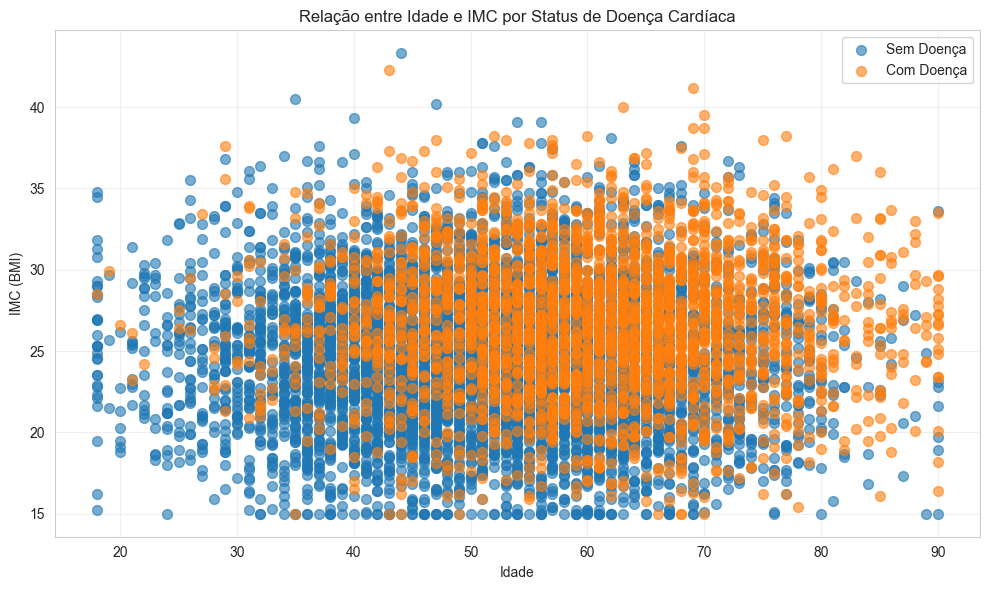

In [15]:
# Scatter plot: Idade vs BMI (colorido por doença cardíaca)
plt.figure(figsize=(10, 6))
for disease in [0, 1]:
    mask = df['has_heart_disease'] == disease
    label = 'Com Doença' if disease == 1 else 'Sem Doença'
    plt.scatter(df[mask]['age'], df[mask]['bmi'], label=label, alpha=0.6, s=50)

plt.xlabel('Idade')
plt.ylabel('IMC (BMI)')
plt.title('Relação entre Idade e IMC por Status de Doença Cardíaca')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Resumo da Análise Exploratória

### Dataset
- **9.000 pacientes**, **27 colunas** (26 features + 1 target)
- Variáveis: numéricas inteiras/float, categóricas (object) e booleanas
- **Nenhum valor ausente** encontrado

### Outliers (método IQR)
- Presença de outliers em 18 das 21 variáveis numéricas
- Os mais expressivos:  (5,4%),  (4,8%)
- **Decisão:** manter — em dados médicos, valores extremos costumam representar casos clínicos reais

### Correlações relevantes (|r| ≥ 0,7)
| Par de variáveis | Correlação |
|---|---|
|  ×  | +0,877 |
|  ×  | +0,841 |
|  ×  | +0,767 |
|  ×  | −0,731 |

A alta correlação entre colesterol total e LDL indica **multicolinearidade** a ser tratada na modelagem.

### Distribuição dos targets
- **Regressão ():** variável contínua, range 93–210 bpm, desvio padrão de 21 — variabilidade adequada para modelagem
- **Classificação ():** 69,7% sem doença × 30,3% com doença — moderadamente desbalanceado, mas dentro do aceitável

### Visualizações geradas
1. Histogramas das 9 principais variáveis numéricas
2. Distribuição (barras + pizza) da variável alvo de classificação
3. Scatter plot Idade × IMC colorido por status de doença
4. Boxplots de outliers (5×5 subplots)
5. Heatmap da matriz de correlação